# 4. Evaluación de modelos

Para cada uno de los 7 modelos se elige el optimizador con menor RMSE externo medio (selección hecha
con la CV anidada, no con el conjunto de prueba). El modelo final de esa combinación (búsqueda sobre todo
el desarrollo) se evalúa **una sola vez** en el hold-out de 139 activos no vistos.

In [1]:
import sys, warnings, json, pickle
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import config as C
from src.data import load_model_data, split_dev_test, xyg, outer_cv
from src.models import MODELS, MODEL_ORDER
from src.nested_cv import collect, regression_metrics
from src.evaluation import residual_diagnostics, acf, ljung_box, bds_test, normality, white_test
from src.viz import set_style, MODEL_COLORS, SPLIT_COLORS, SERIES, INK2, MUTED

C.set_global_seed()
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

df = load_model_data()
dev, test = split_dev_test(df)
X, y, g = xyg(dev)
Xt, yt, _ = xyg(test)
res = [r for r in collect() if r["scenario"] == "A_estructural"]
mt = pd.read_csv(C.RESULTS_DIR / "master_table.csv")
mtA = mt[mt.scenario == "A_estructural"]
best = mtA.loc[mtA.groupby("model")["outer_rmse_mean"].idxmin()].set_index("model").loc[MODEL_ORDER]
finals = {m: next(r for r in res if r["model"] == m and r["method"] == best.loc[m, "method"] and r["fold"] == "final")
          for m in MODEL_ORDER}
pipes = {m: pickle.load(open(C.MODELS_DIR / f"A_estructural__{m}__{best.loc[m, 'method']}.pkl", "rb")) for m in MODEL_ORDER}
best_model = best["outer_rmse_mean"].idxmin()
print("Mejor modelo por RMSE externo:", best_model, "con", best.loc[best_model, "method"])
best[["method", "outer_rmse_mean", "outer_rmse_std", "outer_mae_mean", "outer_r2_mean"]]

Mejor modelo por RMSE externo: RandomForest con Random


,method,outer_rmse_mean,outer_rmse_std,outer_mae_mean,outer_r2_mean
model,,,,,
KNN,Bayesiana,2.613,0.659,1.358,0.758
Ridge,Random,2.683,0.553,1.735,0.749
Lasso,Bayesiana,2.705,0.575,1.753,0.744
DecisionTree,Genetica,2.448,0.886,1.242,0.778
RandomForest,Random,2.008,0.549,1.095,0.856
XGBoost,Grid,2.057,0.600,1.176,0.848
SVR,Bayesiana,2.187,0.529,1.242,0.835


## 4.1 Líneas base de referencia

Se reentrenan con la misma partición las líneas base del entregable 1: `DummyRegressor` (media) y SVR
lineal, en ambos escenarios de variables.

In [2]:
from sklearn.dummy import DummyRegressor
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from src.data import make_preprocessor

baselines = {}
for sc in ["A_estructural", "B_con_BD"]:
    Xa, ya, _ = xyg(dev, sc)
    Xb, _, _ = xyg(test, sc)
    for name, est in [("Dummy (media)", DummyRegressor()), ("SVR lineal (E1)", SVR(kernel="linear"))]:
        p = Pipeline([("prep", make_preprocessor(sc)), ("model", est)]).fit(Xa, ya)
        baselines[(name, sc)] = p.predict(Xb)
pd.DataFrame([{"modelo": n, "escenario": sc, **regression_metrics(yt, pr)} for (n, sc), pr in baselines.items()])

,modelo,escenario,rmse,mae,mape,r2
0,Dummy (media),A_estructural,5.822,4.268,31.870,-0.004
1,SVR lineal (E1),A_estructural,2.719,1.502,9.667,0.781
2,Dummy (media),B_con_BD,5.822,4.268,31.870,-0.004
3,SVR lineal (E1),B_con_BD,2.201,1.445,9.696,0.857


## 4.2 Métricas en el conjunto de prueba y pruebas de supuestos

Residuos ordenados por activo y año (el orden natural del panel) para las pruebas de independencia:

- **White** (forma especial con ŷ y ŷ²): H0 homocedasticidad.
- **BDS** (dimensión m = 2, ε = 1.5σ): H0 residuos i.i.d. (detecta dependencia lineal y no lineal).
- **Ljung-Box** (10 rezagos): H0 sin autocorrelación serial.

In [3]:
rows = []
for m in MODEL_ORDER:
    pr = finals[m]["pred"]
    met = regression_metrics(yt, pr)
    dg = residual_diagnostics(yt, pr, m)
    rows.append({"Modelo": m, "Optimizador": best.loc[m, "method"], "RMSE": met["rmse"], "MAE": met["mae"],
                 "MAPE %": met["mape"], "R²": met["r2"], "p-valor (White)": dg["white_p"],
                 "p-valor (BDS, m=2)": dg["bds_p_m2"], "p-valor (Ljung-Box, 10)": dg["ljungbox_p10"],
                 "asimetría resid.": dg["skew"]})
for (n, sc), pr in baselines.items():
    if sc == "A_estructural":
        met = regression_metrics(yt, pr)
        dg = residual_diagnostics(yt, pr, n)
        rows.append({"Modelo": n, "Optimizador": "—", "RMSE": met["rmse"], "MAE": met["mae"], "MAPE %": met["mape"],
                     "R²": met["r2"], "p-valor (White)": dg["white_p"], "p-valor (BDS, m=2)": dg["bds_p_m2"],
                     "p-valor (Ljung-Box, 10)": dg["ljungbox_p10"], "asimetría resid.": dg["skew"]})
test_tbl = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
test_tbl.to_csv(C.RESULTS_DIR / "test_metrics.csv", index=False)
test_tbl

,Modelo,Optimizador,RMSE,MAE,MAPE %,R²,p-valor (White),"p-valor (BDS, m=2)","p-valor (Ljung-Box, 10)",asimetría resid.
0,XGBoost,Grid,1.648,0.940,6.657,0.920,0.000,0.000,0.000,0.610
1,RandomForest,Random,1.717,0.969,6.737,0.913,0.000,0.000,0.000,1.047
2,DecisionTree,Genetica,1.933,1.017,6.938,0.889,0.000,0.000,0.000,-1.119
3,KNN,Bayesiana,2.128,1.204,8.314,0.866,0.000,0.000,0.000,1.456
4,SVR,Bayesiana,2.160,1.097,7.314,0.862,0.000,0.000,0.000,2.091
5,Lasso,Bayesiana,2.640,1.695,11.785,0.794,0.000,0.000,0.000,2.084
6,Ridge,Random,2.670,1.683,11.632,0.789,0.000,0.000,0.000,2.283
7,SVR lineal (E1),—,2.719,1.502,9.667,0.781,0.000,0.000,0.000,2.885
8,Dummy (media),—,5.822,4.268,31.870,-0.004,1.000,0.000,0.000,1.593


**Interpretación.**

- **Desempeño.** XGBoost (RMSE 1.65, MAE 0.94, R² 0.920) y Random Forest (1.72, 0.97, 0.913) son los
  mejores en activos nunca vistos, con un error porcentual medio de ~6.7 %. El SVR lineal del entregable 1,
  reentrenado **sin** `BrentDifferential`, obtiene RMSE 2.72 y R² 0.78: los modelos no lineales reducen el
  RMSE un 39 % frente a él y un 72 % frente al Dummy.
- **Supuestos.** En todos los modelos se rechazan homocedasticidad (White), independencia i.i.d. (BDS) y no
  autocorrelación (Ljung-Box) con p < 0.001. (El Dummy tiene p de White = 1 porque su predicción es
  constante y la regresión auxiliar no tiene variación que explicar.) Con n = 749 las pruebas tienen mucha
  potencia, pero los rechazos no son triviales: la sección 4.4 muestra que vienen de una estructura real
  de los datos (dependencia dentro de cada activo y error creciente con el nivel de costo).
- **Asimetría.** Los residuos de los modelos lineales son muy asimétricos (≈ 2.1–2.9): subestiman
  sistemáticamente los activos caros. Los ensambles reducen la asimetría (0.6–1.0).

## 4.3 Ajuste en entrenamiento, validación y prueba

- **Entrenamiento:** predicción del modelo final sobre el conjunto de desarrollo con el que fue ajustado.
- **Validación:** predicciones *fuera de pliegue* del bucle externo (cada fila predicha por el modelo
  del pliegue que no la vio).
- **Prueba:** hold-out de activos nunca vistos.

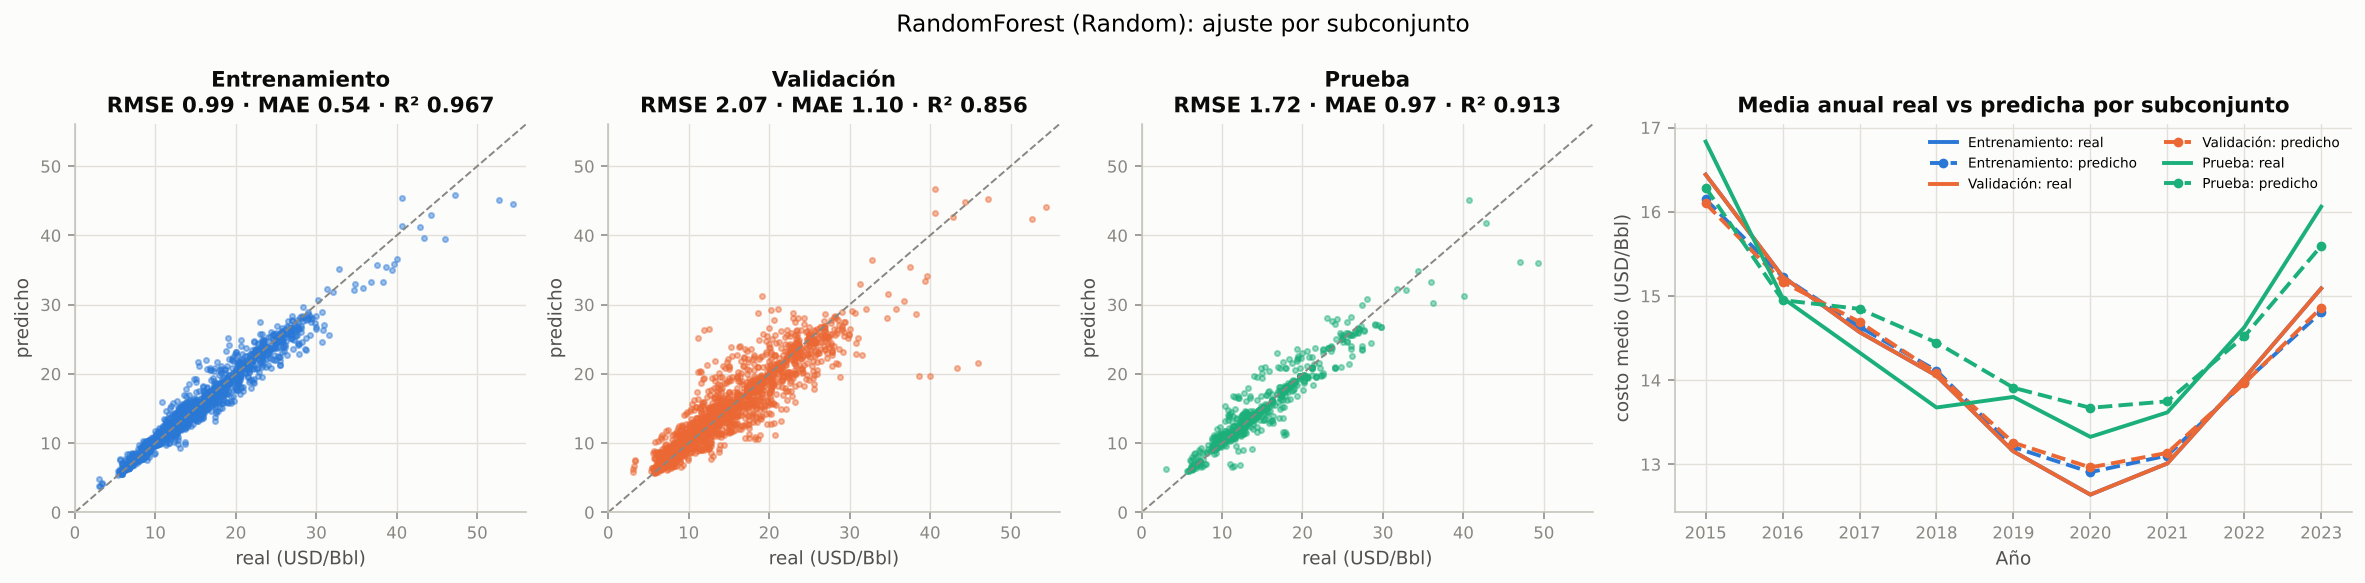

In [4]:
bm, bme = best_model, best.loc[best_model, "method"]
oof = np.full(len(dev), np.nan)
for r in res:
    if r["model"] == bm and r["method"] == bme and r["fold"] != "final":
        oof[r["index"]] = r["pred"]
train_pred = pipes[bm].predict(X)
sets = {"Entrenamiento": (y, train_pred, dev), "Validación": (y, oof, dev), "Prueba": (yt, finals[bm]["pred"], test)}
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2), gridspec_kw={"width_ratios": [1, 1, 1, 1.5]})
lim = [0, max(y.max(), yt.max()) * 1.03]
for ax, (name, (yy, pp, _)) in zip(axes, sets.items()):
    met = regression_metrics(yy, pp)
    ax.scatter(yy, pp, s=7, alpha=0.45, color=SPLIT_COLORS[name])
    ax.plot(lim, lim, color=MUTED, ls="--", lw=1)
    ax.set(xlim=lim, ylim=lim, xlabel="real (USD/Bbl)", ylabel="predicho", title=f"{name}\nRMSE {met['rmse']:.2f} · MAE {met['mae']:.2f} · R² {met['r2']:.3f}")
ax = axes[3]
for name, (yy, pp, frame) in sets.items():
    t = pd.DataFrame({"Year": frame["Year"].values, "y": yy, "p": pp}).groupby("Year").agg(["mean", "count"])
    t = pd.DataFrame({"y": t[("y", "mean")], "p": t[("p", "mean")]})[t[("y", "count")] >= 10]  # 2014 tiene 3 filas
    ax.plot(t.index, t["y"], color=SPLIT_COLORS[name], lw=2, label=f"{name}: real")
    ax.plot(t.index, t["p"], color=SPLIT_COLORS[name], lw=2, ls="--", marker="o", ms=4, label=f"{name}: predicho")
ax.set(xlabel="Año", ylabel="costo medio (USD/Bbl)", title="Media anual real vs predicha por subconjunto")
ax.legend(fontsize=7, ncol=2)
fig.suptitle(f"{bm} ({bme}): ajuste por subconjunto", fontsize=12)
plt.tight_layout()

**Interpretación.**

- **Entrenamiento (RMSE 0.99, R² 0.967) vs validación (2.07, R² 0.856):** la brecha indica que el bosque
  memoriza parte de la estructura de cada activo visto (es esperable en Random Forest, cuyos árboles
  profundos interpolan los datos de entrenamiento). La medida honesta de generalización es la de validación
  y prueba, no la de entrenamiento.
- **Prueba (1.72, R² 0.913)** queda dentro del rango de los pliegues externos (1.5–3.5) y por debajo del
  RMSE de validación agrupado, que incluye un pliegue particularmente difícil (RMSE ≈ 3.5). Además, el
  modelo final se entrena con todo el desarrollo (~10 % más datos que cada modelo externo). La prueba no es
  "más fácil": tiene más varianza (σ 5.8 vs 5.5) y más activos no convencionales (6 % vs 3.4 %), lo que eleva
  el R² a igual RMSE.
- **Serie anual (panel derecho; se omite 2014, que solo tiene 3 filas):** el modelo reproduce la forma en U
  del ciclo de costos 2015–2023 en los tres subconjuntos, con desviaciones de la media anual menores a
  ~0.5 USD/Bbl. El componente temporal común está bien capturado; el error está en el nivel de cada activo.

## 4.4 Análisis de residuos del mejor modelo (prueba)

White: LM = 117.72, p = 2.74e-26
Jarque-Bera p = 0 | Shapiro-Wilk p = 5.43e-28 | asimetría = 1.05 | curtosis exceso = 9.91


,lag,Q,p_value
0,1,226.018,0.000
1,5,320.529,0.000
2,10,341.303,0.000
3,20,354.033,0.000


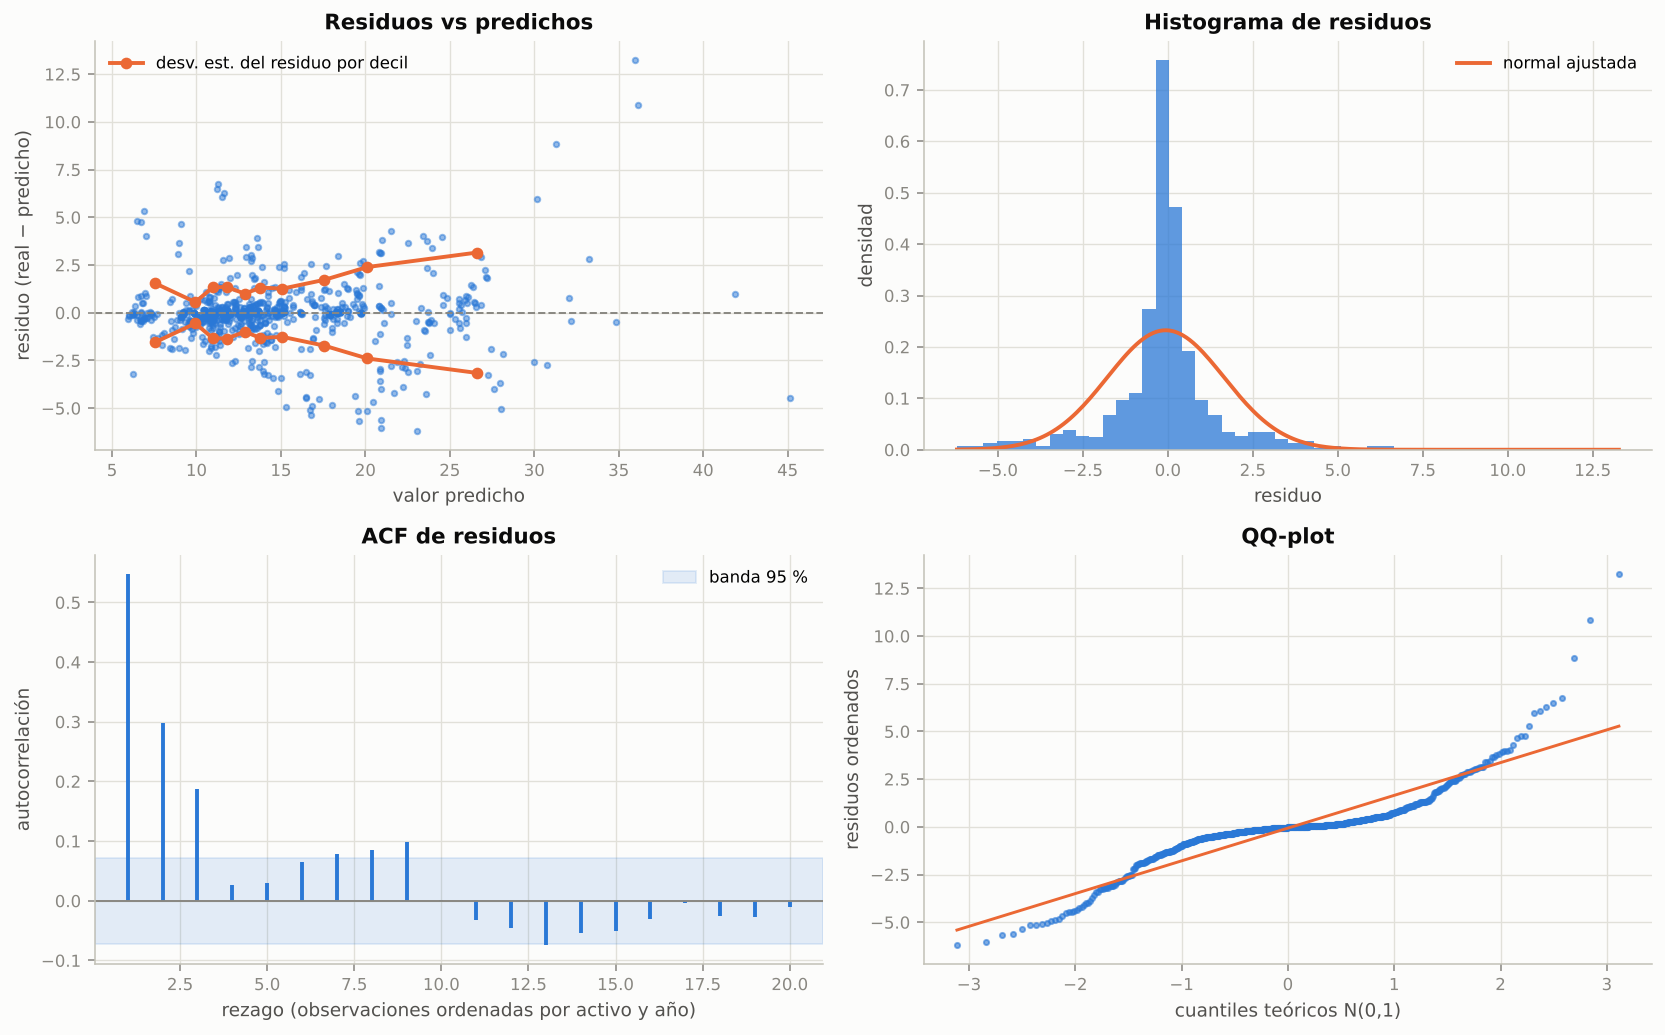

,dim,bds,p_value
0,2,19.682,0.000
1,3,19.904,0.000
2,4,19.566,0.000


In [5]:
e = yt - finals[bm]["pred"]
f = finals[bm]["pred"]
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
axes[0, 0].scatter(f, e, s=8, alpha=0.5, color=SERIES[0])
axes[0, 0].axhline(0, color=MUTED, ls="--", lw=1)
bins = pd.qcut(f, 10)
q = pd.DataFrame({"f": f, "e": e, "b": bins}).groupby("b", observed=True).agg(f=("f", "mean"), sd=("e", "std"))
axes[0, 0].plot(q["f"], q["sd"], color=SERIES[1], marker="o", label="desv. est. del residuo por decil")
axes[0, 0].plot(q["f"], -q["sd"], color=SERIES[1], marker="o")
axes[0, 0].set(xlabel="valor predicho", ylabel="residuo (real − predicho)", title="Residuos vs predichos")
axes[0, 0].legend()
xs = np.linspace(e.min(), e.max(), 200)
axes[0, 1].hist(e, bins=50, density=True, color=SERIES[0], alpha=0.75)
axes[0, 1].plot(xs, stats.norm.pdf(xs, e.mean(), e.std()), color=SERIES[1], lw=2, label="normal ajustada")
axes[0, 1].set(xlabel="residuo", ylabel="densidad", title="Histograma de residuos")
axes[0, 1].legend()
r = acf(e, 20)
n = len(e)
axes[1, 0].vlines(range(1, 21), 0, r[1:], color=SERIES[0], lw=2)
axes[1, 0].axhspan(-1.96 / np.sqrt(n), 1.96 / np.sqrt(n), color=SERIES[0], alpha=0.12, label="banda 95 %")
axes[1, 0].axhline(0, color=MUTED, lw=1)
axes[1, 0].set(xlabel="rezago (observaciones ordenadas por activo y año)", ylabel="autocorrelación", title="ACF de residuos")
axes[1, 0].legend()
osm, osr = stats.probplot(e, dist="norm", fit=False)
axes[1, 1].scatter(osm, np.sort(e), s=7, color=SERIES[0], alpha=0.6)
lo_hi = np.array([osm.min(), osm.max()])
axes[1, 1].plot(lo_hi, e.mean() + e.std() * lo_hi, color=SERIES[1], lw=1.5)
axes[1, 1].set(xlabel="cuantiles teóricos N(0,1)", ylabel="residuos ordenados", title="QQ-plot")
plt.tight_layout()
lb = ljung_box(e, (1, 5, 10, 20))
bd = bds_test(e, 4)
nm = normality(e)
wt = white_test(e, f)
print(f"White: LM = {wt['lm']:.2f}, p = {wt['p_value']:.3g}")
print(f"Jarque-Bera p = {nm['jb_p']:.3g} | Shapiro-Wilk p = {nm['shapiro_p']:.3g} | asimetría = {nm['skew']:.2f} | curtosis exceso = {nm['kurtosis_excess']:.2f}")
display(lb)
bd

In [6]:
# Autocorrelación dentro de cada activo (rezago 1 entre años consecutivos del mismo activo)
tt = test.assign(e=e).sort_values([C.GROUP, "Year"])
tt["e_lag"] = tt.groupby(C.GROUP)["e"].shift(1)
pair = tt.dropna(subset=["e_lag"])
rho, p_rho = stats.pearsonr(pair["e"], pair["e_lag"])
print(f"Correlación del residuo con el del año anterior del MISMO activo: ρ = {rho:.3f} (p = {p_rho:.2g}, n = {len(pair)})")
by_asset = tt.groupby(C.GROUP)["e"].agg(["mean", "std", "count"])
print(f"Desv. est. de la media del residuo entre activos: {by_asset['mean'].std():.2f} | desv. est. media dentro de un activo: {by_asset['std'].mean():.2f}")

Correlación del residuo con el del año anterior del MISMO activo: ρ = 0.752 (p = 2.8e-112, n = 610)
Desv. est. de la media del residuo entre activos: 1.67 | desv. est. media dentro de un activo: 0.74


**Interpretación.**

- **Heterocedasticidad (White p ≈ 10⁻²⁶).** La desviación del residuo crece con el valor predicho: los
  activos caros (no convencionales, arenas bituminosas) tienen errores mucho mayores en términos absolutos.
  Implicación práctica: reportar el error en términos relativos (MAPE ≈ 6.7 %) o modelar log(costo) como
  trabajo futuro.
- **No normalidad.** Curtosis en exceso ≈ 9.9 y asimetría ≈ 1.05: la mayoría de los errores son pequeños
  (MAE 0.97), pero unos pocos activos concentran errores de 10–15 USD/Bbl (colas pesadas).
- **Dependencia (Ljung-Box y BDS, p ≈ 0).** Con los residuos ordenados por activo y año, el residuo de un año
  está muy correlacionado con el del año anterior **del mismo activo** (ρ = 0.75). La desviación de la media
  del residuo entre activos (1.67) duplica la variación dentro de cada activo (0.74). En otras palabras, el
  modelo comete un error **persistente por activo**: acierta el nivel de su región, tipo y país, pero cada
  campo tiene un "efecto propio" (geología, antigüedad, contratos) que las variables disponibles no explican.
- **Implicaciones.** (i) Es la razón por la que se usó partición por grupos: con partición aleatoria el
  modelo habría visto otros años del mismo activo y el error parecería mucho menor. (ii) En un caso de uso de
  **pronóstico** para activos existentes, agregar el costo del año anterior (rezago) capturaría ese efecto
  propio; en el caso de uso de este proyecto (activos nuevos, sin historia) ese rezago no está disponible.
  (iii) Los intervalos y pruebas sobre el hold-out deben respetar esta dependencia: por eso el capítulo 5 usa
  bootstrap estacionario por bloques.

## 4.5 Robustez y estabilidad de las métricas

### Media ± desviación estándar a través de los pliegues externos

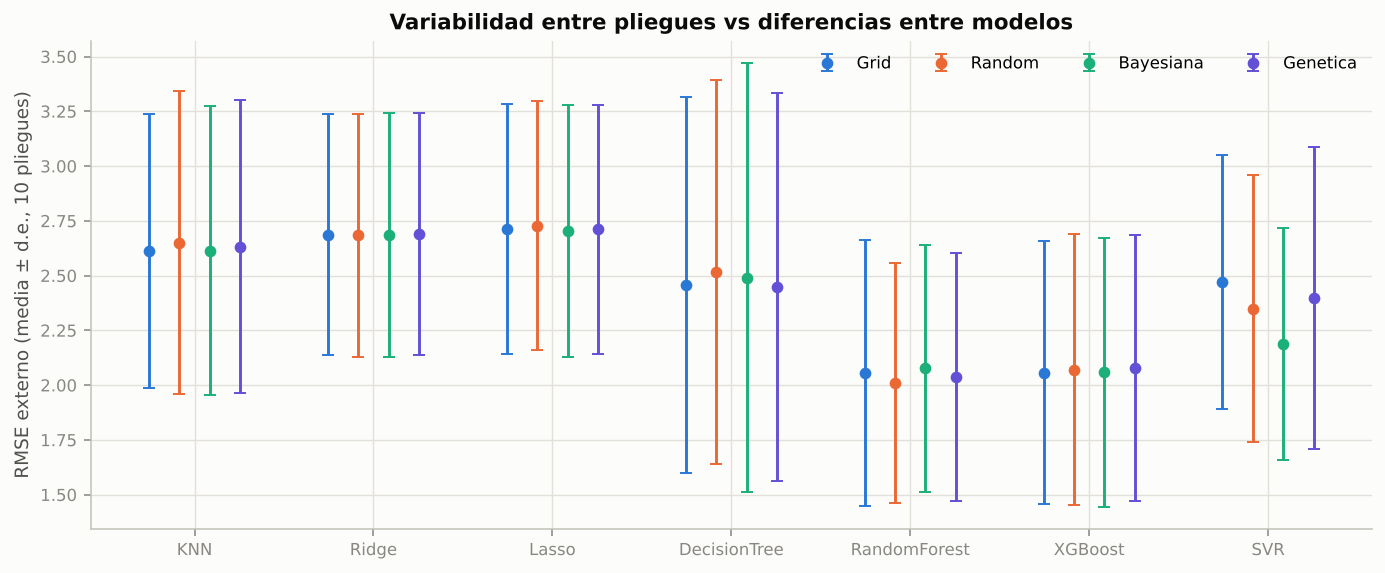

,RMSE medio,d.e. entre pliegues,CV entre pliegues (%)
model,,,
KNN,2.613,0.659,25.234
Ridge,2.683,0.553,20.602
Lasso,2.705,0.575,21.266
DecisionTree,2.448,0.886,36.212
RandomForest,2.008,0.549,27.317
XGBoost,2.057,0.600,29.185
SVR,2.187,0.529,24.176


In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
mtA_ = mtA.copy()
methods = ["Grid", "Random", "Bayesiana", "Genetica"]
xpos = np.arange(len(MODEL_ORDER))
from src.viz import METHOD_COLORS
for k, me in enumerate(methods):
    s = mtA_[mtA_.method == me].set_index("model").loc[MODEL_ORDER]
    ax.errorbar(xpos + (k - 1.5) * 0.17, s.outer_rmse_mean, yerr=s.outer_rmse_std, fmt="o", ms=5, capsize=3,
                color=METHOD_COLORS[me], label=me, lw=1.5)
ax.set_xticks(xpos, MODEL_ORDER)
ax.set(ylabel="RMSE externo (media ± d.e., 10 pliegues)", title="Variabilidad entre pliegues vs diferencias entre modelos")
ax.legend(ncol=4)
plt.tight_layout()
var_ratio = pd.DataFrame({
    "RMSE medio": best["outer_rmse_mean"], "d.e. entre pliegues": best["outer_rmse_std"],
    "CV entre pliegues (%)": 100 * best["outer_rmse_std"] / best["outer_rmse_mean"]})
var_ratio

### Sensibilidad a la semilla de inicialización del modelo

Los modelos finales con aleatoriedad interna (árbol, Random Forest, XGBoost) se reentrenan con 10
semillas manteniendo los hiperparámetros, y se mide el RMSE en prueba.

In [8]:
rows = []
for m in ["DecisionTree", "RandomForest", "XGBoost"]:
    params = json.loads(best.loc[m, "final_params"])
    for sd in range(10):
        p = MODELS[m].make_pipeline(params, C.MAIN_SCENARIO, seed=sd).fit(X, y)
        rows.append({"model": m, "seed": sd, "rmse": float(np.sqrt(np.mean((yt - p.predict(Xt)) ** 2)))})
seed_m = pd.DataFrame(rows)
seed_m.to_csv(C.RESULTS_DIR / "seed_model_sensitivity.csv", index=False)
seed_m.groupby("model")["rmse"].agg(["mean", "std", "min", "max"])

,mean,std,min,max
model,,,,
DecisionTree,1.934,0.002,1.932,1.936
RandomForest,1.728,0.013,1.713,1.750
XGBoost,1.683,0.011,1.669,1.704


**Interpretación.**

- **Entre pliegues** el coeficiente de variación del RMSE es del 21–36 %: el error depende mucho de qué
  activos caen en cada pliegue (p. ej., si un pliegue contiene varias arenas bituminosas canadienses). El
  árbol de decisión es el más inestable (CV 36 %).
- **Entre semillas** la variación es mínima: desviación del RMSE de prueba de 0.002 (árbol), 0.013 (Random
  Forest) y 0.011 (XGBoost). La semilla aporta ~50 veces menos incertidumbre que la partición.
- **¿Las diferencias entre modelos superan la variabilidad?** Entre familias, sí en parte: el salto de
  ensambles (≈ 2.0) a lineales (≈ 2.7) es mayor que una desviación entre pliegues (≈ 0.55). Entre Random
  Forest y XGBoost (2.01 vs 2.06), o entre optimizadores de un mismo modelo, la diferencia es diez veces menor
  que la desviación entre pliegues. Como los pliegues son los mismos para todos los modelos (diseño pareado),
  la comparación correcta no es "media ± d.e." sino pruebas sobre rangos pareados: eso es lo que hace el
  capítulo 5.

## 4.6 Interpretabilidad con SHAP

Los valores de Shapley reparten la predicción de cada observación entre las variables cumpliendo
**eficiencia** (las contribuciones suman la predicción menos el valor base), **simetría** (variables
intercambiables reciben igual contribución) y **aditividad** (la contribución en un ensamble es la suma de
las contribuciones en cada árbol). Se usa `TreeExplainer`, que calcula valores exactos para árboles.
Como el Pipeline aplica One-Hot, las contribuciones de las columnas de una misma variable se suman
(por aditividad) para leer el efecto de la variable original.

Modelo explicado: RandomForest | verificación de eficiencia (máx |Σφ + base − ŷ|): 9.41e-12


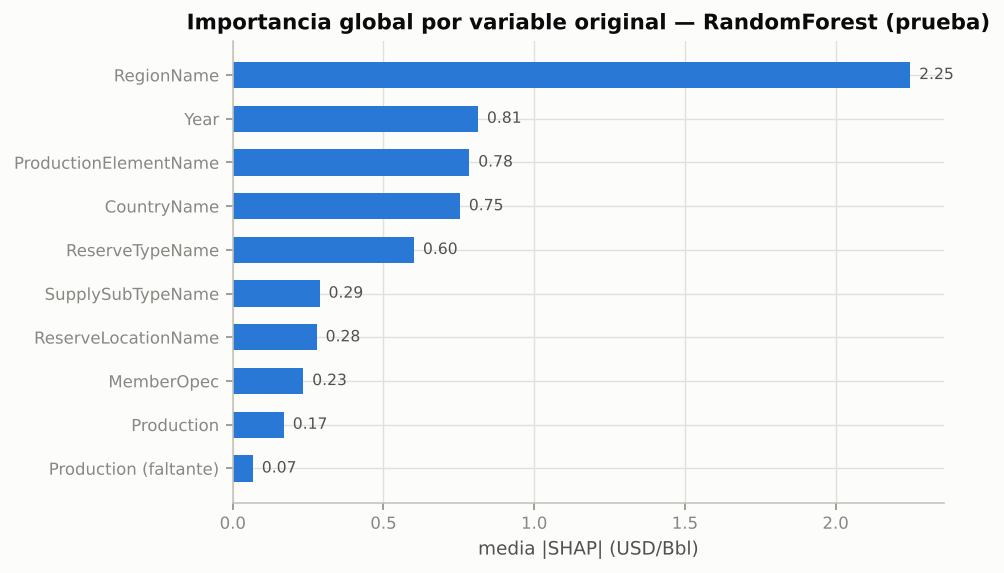

In [9]:
import shap
from src.interpret import shap_values, lime_explain

tree_models = ["RandomForest", "XGBoost", "DecisionTree"]
shap_model = bm if bm in tree_models else min(tree_models, key=lambda m: best.loc[m, "outer_rmse_mean"])
sv, sv_agg = shap_values(pipes[shap_model], Xt)
check = np.abs(sv.values.sum(1) + sv.base_values - pipes[shap_model].predict(Xt)).max()
print(f"Modelo explicado: {shap_model} | verificación de eficiencia (máx |Σφ + base − ŷ|): {check:.2e}")
imp = pd.Series(np.abs(sv_agg.values).mean(0), index=sv_agg.feature_names).sort_values(ascending=False)
imp.to_frame("media |SHAP| (USD/Bbl)").to_csv(C.RESULTS_DIR / "shap_importance.csv")
fig, ax = plt.subplots(figsize=(7, 4.2))
imp_s = imp.sort_values()
ax.barh(imp_s.index, imp_s.values, color=SERIES[0], height=0.6)
for yv, v in enumerate(imp_s.values):
    ax.text(v + 0.03, yv, f"{v:.2f}", va="center", fontsize=8, color=INK2)
ax.set(xlabel="media |SHAP| (USD/Bbl)", title=f"Importancia global por variable original — {shap_model} (prueba)")
plt.tight_layout()

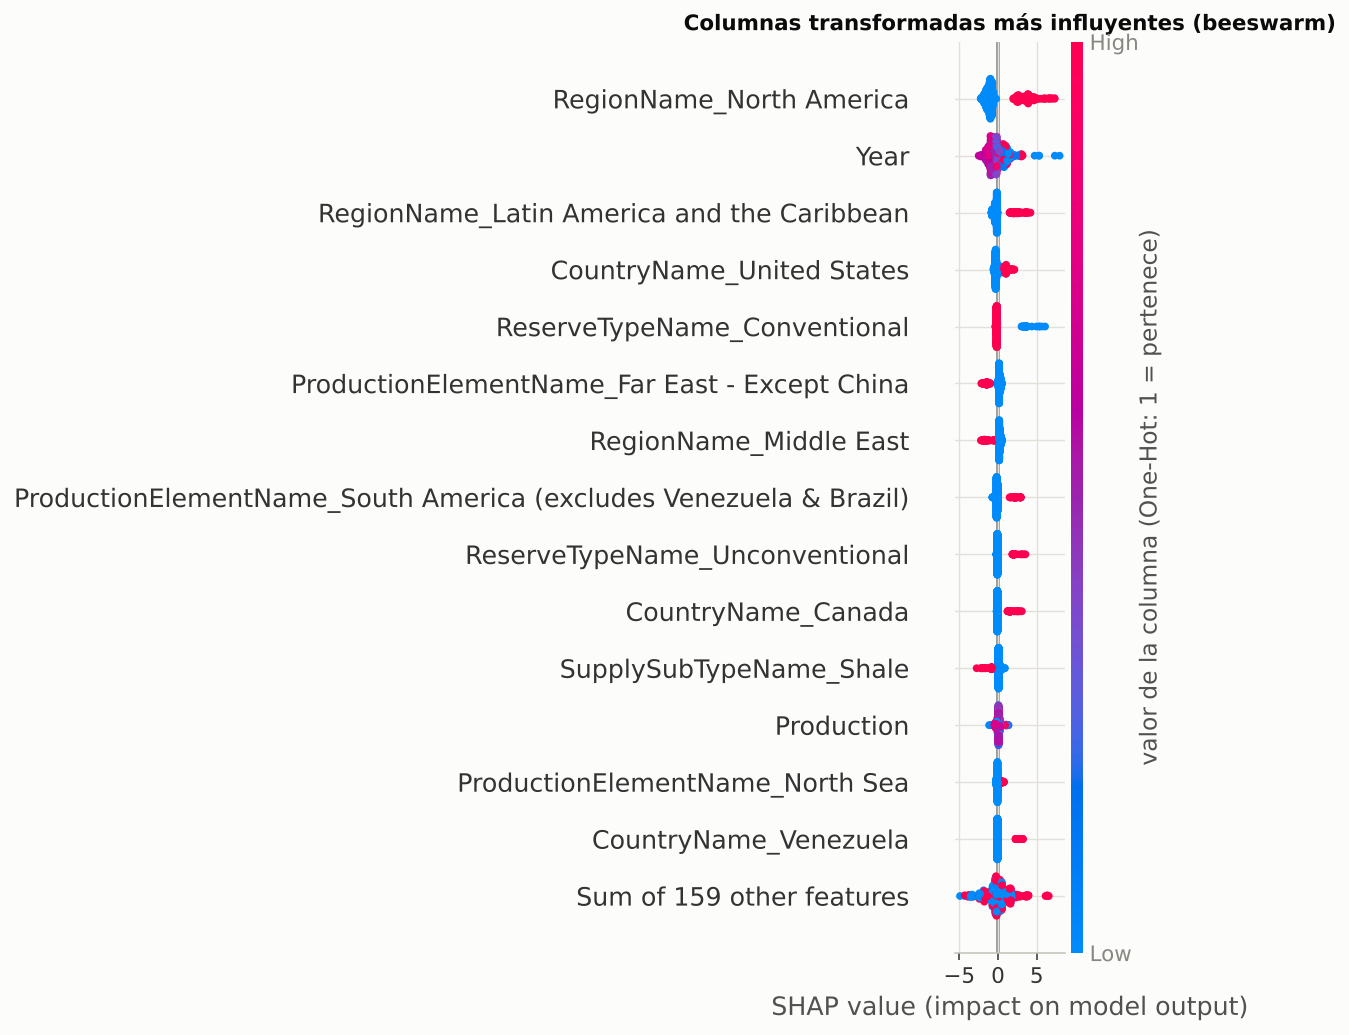

,media |SHAP|
RegionName,2.247
Year,0.813
ProductionElementName,0.784
CountryName,0.753
ReserveTypeName,0.601
SupplySubTypeName,0.288
ReserveLocationName,0.278
MemberOpec,0.234
Production,0.169
Production (faltante),0.066


In [10]:
plt.figure()
shap.plots.beeswarm(sv, max_display=15, show=False, color_bar_label="valor de la columna (One-Hot: 1 = pertenece)")
plt.title("Columnas transformadas más influyentes (beeswarm)")
plt.tight_layout()
imp.to_frame("media |SHAP|")

**Interpretación.**

- **La región domina** (media |SHAP| ≈ 2.2 USD/Bbl): por sí sola mueve la predicción más que las tres
  variables siguientes juntas. El beeswarm de columnas One-Hot muestra cómo: pertenecer a *North America* sube
  el costo entre +2 y +7 USD/Bbl, *Latin America and the Caribbean* entre +1 y +4, y *Middle East* o la cuenca
  *Far East – Except China* lo bajan ~2–3 USD/Bbl.
- **`Year`** (≈ 0.8) es la segunda: captura el ciclo de costos (más altos en 2015–2016 y 2022–2023).
- **`ProductionElementName` y `CountryName`** (≈ 0.75–0.8 cada una) afinan dentro de la región.
- **`ReserveTypeName`** tiene importancia media moderada (0.6) porque solo el 6 % de los activos son no
  convencionales, pero cuando aplica su efecto es de los mayores del modelo (+3 a +10 USD/Bbl). Un detalle
  interesante: el subtipo *Shale* (que la fuente clasifica como reserva convencional) **reduce** la
  predicción ~1–3 USD/Bbl una vez considerada la región.
- **`Production`** aporta poco (0.17): la escala de producción no explica el costo unitario una vez se
  conoce la geografía y el tipo de activo, coherente con su correlación débil en el EDA (ρ ≈ −0.11). Su
  indicador de faltante casi no aporta (0.07) porque la ausencia está determinada por la región.
- La propiedad de **eficiencia** se verificó numéricamente: Σφ + valor base = ŷ con error máximo de 10⁻¹¹.

### Explicaciones locales: una predicción precisa y una con error alto

,CostProductionElementName,CountryName,SupplySubTypeName,ReserveLocationName,Year,real,predicho
precisa,Gulf of Mexico SLI,United States,Non-Shale,Offshore Deep,2019,11.580,11.580
error alto,Bitumen Mined,Canada,Bitumen,Onshore,2015,49.230,35.960


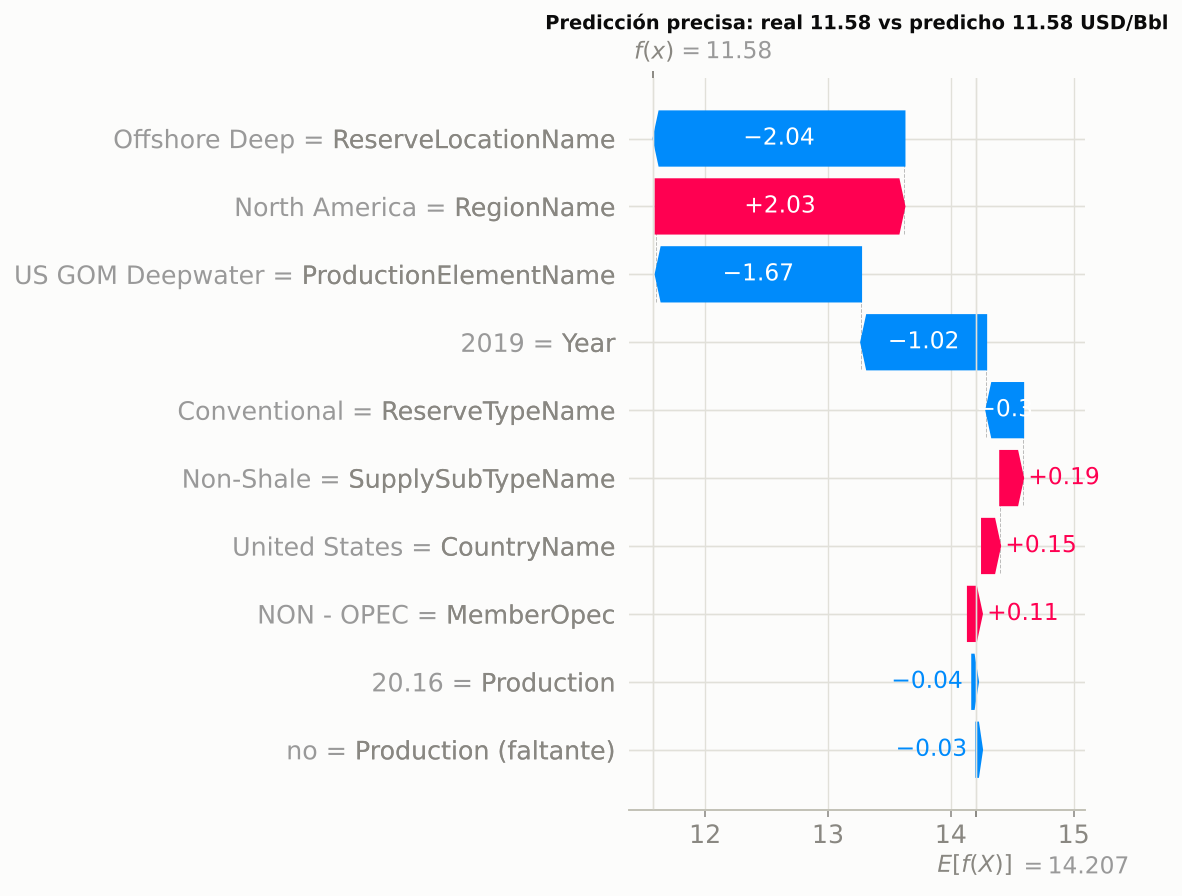

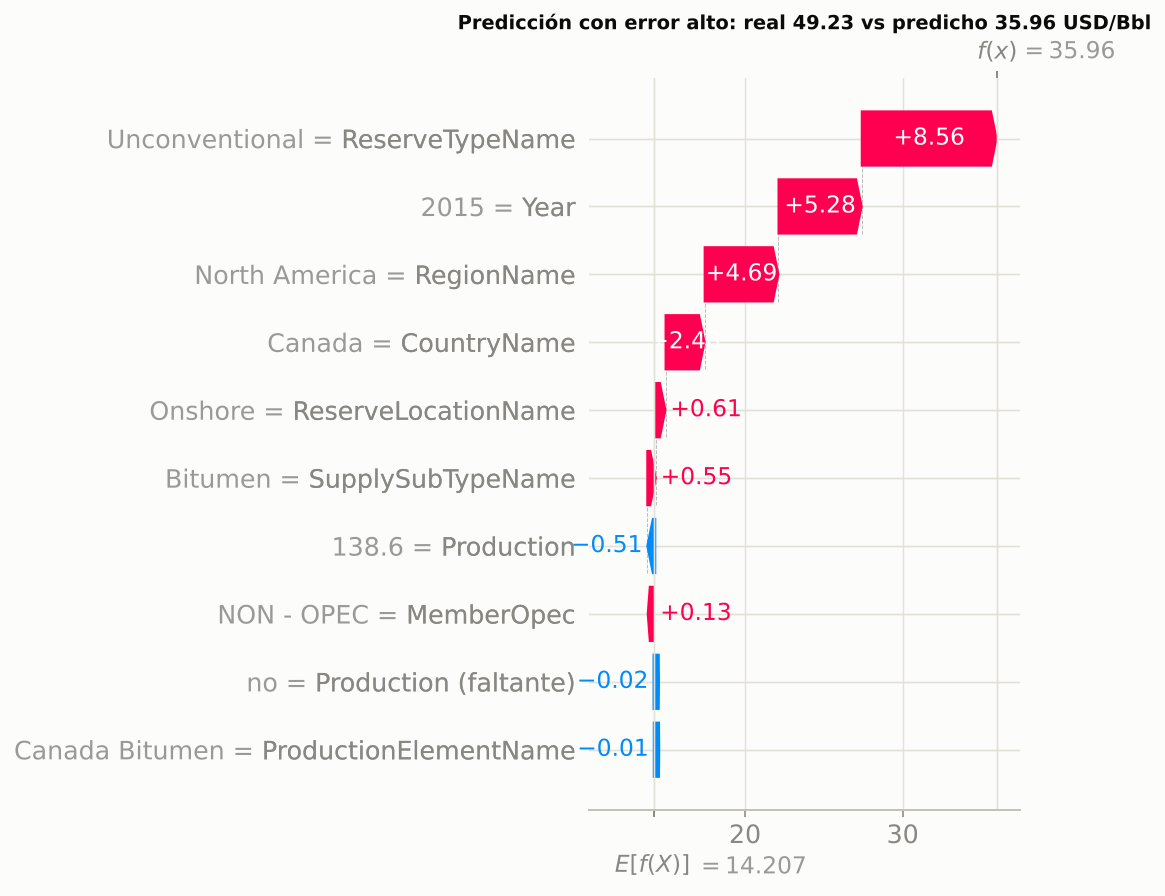

In [11]:
pred_s = pipes[shap_model].predict(Xt)
err = yt - pred_s
i_good = int(np.argmin(np.abs(err) + (np.abs(yt - np.median(yt)) > 4) * 99))  # precisa y en zona típica
i_bad = int(np.argmax(np.abs(err)))
info = test.iloc[[i_good, i_bad]][[C.GROUP, "CountryName", "SupplySubTypeName", "ReserveLocationName", "Year"]].copy()
info["real"] = yt[[i_good, i_bad]]
info["predicho"] = pred_s[[i_good, i_bad]]
info.index = ["precisa", "error alto"]
display(info)
for i, lbl in [(i_good, "Predicción precisa"), (i_bad, "Predicción con error alto")]:
    plt.figure()
    shap.plots.waterfall(sv_agg[i], max_display=10, show=False)
    plt.title(f"{lbl}: real {yt[i]:.2f} vs predicho {pred_s[i]:.2f} USD/Bbl", fontsize=10)
    plt.tight_layout()

**Interpretación.**

- **Predicción precisa** (*Gulf of Mexico SLI*, EE. UU., offshore profundo, 2019; real 11.58 vs 11.58): las
  contribuciones se compensan. Estar en Norteamérica sube el costo (+2.0), pero ser *offshore* profundo (−2.0),
  la cuenca *US GOM Deepwater* (−1.7) y el año 2019, fondo del ciclo (−1.0), lo bajan desde la base de 14.2. El modelo llega al valor exacto por
  combinación de efectos de signo opuesto.
- **Error alto** (*Bitumen Mined*, Canadá, 2015; real 49.23 vs 35.96): el modelo identifica correctamente
  los factores de costo alto (no convencional +8.6, año 2015 +5.3, Norteamérica +4.7, Canadá +2.5), pero se
  queda corto en 13 USD/Bbl. La minería de bitumen es un caso extremo con muy pocos activos parecidos en
  entrenamiento; los árboles promedian hojas con activos no convencionales menos costosos y no pueden
  extrapolar por encima de lo visto. Es el mismo patrón de error persistente por activo de la sección 4.4.

## 4.7 XGBoost: SHAP vs LIME

La guía pide analizar XGBoost con ambas técnicas. Se explican las mismas dos observaciones.

In [12]:
sv_x, sv_x_agg = shap_values(pipes["XGBoost"], Xt)
px_ = pipes["XGBoost"].predict(Xt)
out = []
for i, lbl in [(i_good, "precisa"), (i_bad, "error alto")]:
    le = lime_explain(pipes["XGBoost"], X, Xt.iloc[[i]], num_features=8)
    sh = pd.Series(sv_x_agg.values[i], index=sv_x_agg.feature_names)
    top_shap = sh.abs().sort_values(ascending=False).head(5).index.tolist()
    print(f"\n=== Observación {lbl}: real {yt[i]:.2f}, XGBoost {px_[i]:.2f} | LIME pred. local {le.attrs['local_pred']:.2f} "
          f"(R² del ajuste local = {le.attrs['score_r2_local']:.2f})")
    comp = pd.DataFrame({"SHAP (contribución, USD/Bbl)": sh[top_shap].round(3)})
    display(comp)
    display(le)
    out.append((lbl, top_shap, le))
gl = pd.Series(np.abs(sv_x_agg.values).mean(0), index=sv_x_agg.feature_names).sort_values(ascending=False)
gl.head(8).to_frame("XGBoost: media |SHAP|")


=== Observación precisa: real 11.58, XGBoost 11.74 | LIME pred. local 16.69 (R² del ajuste local = 0.52)

=== Observación error alto: real 49.23, XGBoost 41.85 | LIME pred. local 31.91 (R² del ajuste local = 0.58)


,"SHAP (contribución, USD/Bbl)"
ReserveLocationName,-2.398
RegionName,1.658
ProductionElementName,-1.056
Year,-0.899
CountryName,0.407


,regla,peso
0,ReserveTypeName=Conventional,-6.204
1,RegionName=North America,5.387
2,CountryName=United States,1.502
3,ReserveLocationName=Offshore Deep,-1.440
4,ProductionElementName=US GOM Deepwater,-1.055
5,17.31 < Production <= 42.00,-0.432
6,MemberOpec=NON - OPEC,0.426
7,2017.00 < Year <= 2019.00,-0.280


,"SHAP (contribución, USD/Bbl)"
ReserveTypeName,10.441
Year,7.292
RegionName,6.770
CountryName,1.779
SupplySubTypeName,1.217


,regla,peso
0,ReserveTypeName=Unconventional,6.544
1,RegionName=North America,5.681
2,Year <= 2017.00,1.952
3,SupplySubTypeName=Bitumen,1.726
4,CountryName=Canada,1.504
5,ProductionElementName=Canada Bitumen,1.436
6,ReserveLocationName=Onshore,1.241
7,Production > 99.78,0.710


,XGBoost: media |SHAP|
RegionName,2.200
Year,0.922
CountryName,0.749
ProductionElementName,0.727
ReserveTypeName,0.567
ReserveLocationName,0.317
SupplySubTypeName,0.272
MemberOpec,0.214


**Interpretación: SHAP vs LIME en XGBoost.**

- **Global (XGBoost):** el ranking de SHAP coincide con el de Random Forest (región ≫ año > país ≈ cuenca >
  tipo de reserva), lo que da robustez a la interpretación.
- **Observación con error alto:** ambas técnicas coinciden en las variables (no convencional, Norteamérica,
  año ≤ 2017, bitumen, Canadá) y en el signo (todas suben el costo).
- **Observación precisa:** divergen. SHAP atribuye el mayor efecto a la ubicación *offshore* profunda (−2.4)
  y a la región (+1.7); LIME da el mayor peso a *Conventional* (−6.2) y *North America* (+5.4). Además el
  modelo lineal local de LIME predice 16.7 cuando XGBoost predice 11.7 (R² local = 0.52): la aproximación
  lineal no es fiel en ese vecindario.

**Por qué divergen (diferencias metodológicas).**

1. **Referencia distinta.** SHAP reparte ŷ − E[ŷ] respecto a la media del modelo; LIME estima pesos respecto
   a su propio intercepto local, que depende de la distribución de perturbaciones. Los números no son
   comparables uno a uno, solo el orden y el signo.
2. **Perturbaciones irreales.** LIME muestrea cada variable de forma independiente: genera combinaciones
   imposibles (p. ej., *Canada* con región *Middle East*). Con la jerarquía país → región → cuenca del EDA
   (V de Cramér ≈ 1), el modelo lineal local se ajusta sobre puntos fuera de la distribución.
3. **Discretización y aleatoriedad.** LIME discretiza las numéricas en cuartiles y su resultado cambia con la
   semilla y el número de muestras; TreeSHAP es exacto y determinista para árboles.
4. **Garantías.** SHAP cumple eficiencia, simetría y aditividad; LIME solo garantiza fidelidad local
   aproximada (aquí R² ≈ 0.5–0.6).

**Cuándo divergen:** con variables fuertemente dependientes, con efectos no lineales e interacciones (como la
combinación región × tipo de reserva) y cuando el ajuste lineal local es pobre. En este proyecto SHAP es la
fuente principal de interpretación y LIME sirve como verificación cualitativa.